# Setup

In [ ]:
#@title Setup Dependencies & API Key Round-Robin Manager
import os
import itertools
from openai import OpenAI
from pydantic import BaseModel, Field
from typing import List
from google.colab import userdata
import json


API_KEYS = [
    userdata.get("GEMINI_API_KEY")
]

# Create a cyclic iterator for the keys
key_iterator = itertools.cycle(API_KEYS)

def get_client(iterator = key_iterator, base_url: str = "https://generativelanguage.googleapis.com/v1beta/openai/"):
    key = next(iterator)
    return OpenAI(
        api_key=key,
        base_url=base_url
    )

print("Environment ready. Round-robin key iterator initialized.")

Environment ready. Round-robin key iterator initialized.


In [ ]:
#@title Load `compiled.md` Context
file_path = "/content/compiled.md"

try:
    with open(file_path, "r", encoding="utf-8") as f:
        compiled_context = f.read()
    print(f"Successfully loaded compiled.md!")
    print(f"Total characters: {len(compiled_context):,}")
    print(f"Preview (first 150 chars): \n{compiled_context[:150]}...")
except FileNotFoundError:
    print(f"Error: Could not find {file_path}. Please ensure it is uploaded to the Colab session.")

Successfully loaded compiled.md!
Total characters: 268,134
Preview (first 150 chars): 
# Whole codebase for `animal-data`

### `bird/scales.md`
```md
# Comprehensive Manual for Avian & Poultry Pain and Stress Assessment
**Focus: Facial E...


In [ ]:
#@title [CELL 3] Define Refactored Pydantic Schema (Anti-Lie Architecture)
from pydantic import BaseModel, Field
from typing import List

class TaskCard(BaseModel):
    task_id: str = Field(description="Leave blank for now, assigned programmatically later.")
    species: str = Field(description="Species and breed/strain/life-stage if applicable")
    context_metadata: str = Field(description="The setting, time post-op, observer presence, or environmental state. This is what makes it an edge-case.")
    visual_cues: str = Field(description="Physical, facial, and postural observations.")

    # NEW ARCHITECTURE: Split the logic to prevent clinical lies
    factual_medical_rule: str = Field(description="A 100% true, textbook biological rule from the manual that applies to the visual cues (e.g., 'Orbital tightening is a validated marker of acute pain.').")
    adversarial_distractor: str = Field(description="The actual text of the trap. It MUST ONLY be the factual_medical_rule presented as a Red Herring. DO NOT add false conclusions like 'Therefore it must be in pain.' Let the fact itself be the trap.")

    indicator_class: str = Field(description="e.g., Facial / Physiological / Contextual / Behavioral")
    target_category: str = Field(description="Must be one of: Negative_Nociceptive, Positive_Welfare, Neutral_Resting, False_Positive_Morphological, False_Positive_Physiological, False_Negative_Masking")

    sota_judge_summary: str = Field(description="Chain-of-Thought reasoning explaining why the factual_medical_rule is true in general, BUT fails here because of the context_metadata.")
    source_citation: str = Field(description="Exact quote citation from the text backing up the factual_medical_rule, e.g., [@smith-2023; q='...']")

class TaskBatch(BaseModel):
    tasks: List[TaskCard]

print("Refactored Pydantic schema defined. 'Clinical Lie' barriers are up.")

Refactored Pydantic schema defined. 'Clinical Lie' barriers are up.


In [ ]:
#@title [CELL 4] Validate Generator Pipeline (The "Misapplied Truth" Prompt)
import json

GENERATOR_SYSTEM_PROMPT = """You are an expert veterinary AI data synthesizer building a board-exam level benchmark.
Your goal is to extract "Hard Rules", exceptions, and biological anomalies to create Affective State Assessment task cards.

CRITICAL GUARDRAIL: NO CLINICAL LIES.
A high-quality medical benchmark tests robustness, not hallucination spotting.
Your `adversarial_distractor` MUST NOT contain fake biology or fabricated absolute words (like "must", "always", "definitive proof").

HOW TO BUILD A TRAP (THE "MISAPPLIED TRUTH"):
1. Find a 100% true rule in the text (e.g., "The EquiFACS manual states backward ears indicate nociception.")
2. Create a scenario where that rule is naturally broken by context (e.g., A dog that just finished a vigorous run).
3. The distractor is simply stating the true rule. The AI being tested will fail if it blindly applies the rule without reading the context.

TARGET CATEGORY DISTRIBUTION:
Ensure a diverse mix of: Negative_Nociceptive, Positive_Welfare, Neutral_Resting, False_Positive_Morphological, False_Positive_Physiological, False_Negative_Masking.
Generate exactly {N} task cards.
"""

def generate_test_batch(context_text: str, n: int = 4):
    client = get_client() # Grabs the next key

    print("Sending request to Gemini 3.1 Flash Lite via OpenAI SDK...")
    response = client.beta.chat.completions.parse(
        model="gemini-3.1-flash-lite",
        messages=[
            {"role": "system", "content": GENERATOR_SYSTEM_PROMPT.format(N=n)},
            {"role": "user", "content": f"Here is the compiled manual data. Generate {n} unique tasks focusing on 'Hard Rules' and edge-cases.\n\n{context_text}"}
        ],
        response_format=TaskBatch,
        temperature=0.8, # Lowered slightly from 1.0 to increase factual adherence
        reasoning_effort="high"
    )

    return response.choices[0].message.parsed

# Run the test (Assuming compiled_context is still in memory from Cell 2)
if 'compiled_context' in locals():
    try:
        # We will just pass a small slice of the context for the test run
        test_batch = generate_test_batch(compiled_context[:10000], n=2)
        print("\n--- TEST GENERATION SUCCESSFUL ---\n")
        print(json.dumps(test_batch.model_dump(), indent=2))
    except Exception as e:
        print(f"API Error: {e}")
else:
    print("Please run Cell 2 to load the context first.")

Sending request to Gemini 3.1 Flash Lite via OpenAI SDK...

--- TEST GENERATION SUCCESSFUL ---

{
  "tasks": [
    {
      "task_id": "AV-SC-001",
      "species": "Silkie Chicken",
      "context_metadata": "Healthy adult individual observed in a standard poultry enclosure with no signs of lethargy or injury.",
      "visual_cues": "Ruffled plumage (neck and breast), low wing carriage.",
      "factual_medical_rule": "The Stressed Chicken Scale (SCS) evaluates plumage fullness and wing position, where ruffled feathers and drooping wings are classified as Negative_Nociceptive signals.",
      "adversarial_distractor": "Ruffled or fluffed feathers and low wing carriage are standard indicators of a Negative_Nociceptive state according to the Stressed Chicken Scale.",
      "indicator_class": "Behavioral",
      "target_category": "False_Positive_Morphological",
      "sota_judge_summary": "While the SCS uses plumage and wing position as valid stress markers, these markers are confounded 

In [ ]:
#@title [CELL 4.5] Forgiving Citation Validator (Handles Ellipses)
import re
import string

def normalize_text(text: str) -> str:
    """Removes punctuation, lowercases, and collapses whitespace."""
    text = re.sub(r'[^\w\s]', '', text).lower()
    return " ".join(text.split())

def validate_citations(tasks: list, source_text: str) -> list:
    """
    Checks if the generated quote exists in the source text.
    Handles LLM abbreviations using ellipses (... or …).
    """
    valid_tasks = []
    source_norm = normalize_text(source_text)

    for task in tasks:
        # Allow either dict-style or object-style access depending on Pydantic state
        citation = task.get("source_citation", "") if isinstance(task, dict) else getattr(task, "source_citation", "")

        match = re.search(r'q=["\'](.*?)["\']', citation)

        if match:
            raw_quote = match.group(1)
            quote_chunks = re.split(r'\.{2,}|…', raw_quote)

            all_chunks_found = True
            for chunk in quote_chunks:
                chunk_norm = normalize_text(chunk)
                if len(chunk_norm.split()) < 3: # Ignore tiny fragments
                    continue

                if chunk_norm not in source_norm:
                    all_chunks_found = False
                    print(f"❌ REJECTED CITATION: Could not find this specific part: '{chunk_norm}'")
                    break

            if all_chunks_found:
                valid_tasks.append(task)
        else:
            print(f"❌ MALFORMED CITATION: Could not extract quote from: {citation}")

    return valid_tasks

print("Forgiving Citation Validator Ready.")

Forgiving Citation Validator Ready.


In [ ]:
#@title [CELL 4.6] Validate Test Cell Citations (Sanity Check)

if 'test_batch' in locals() and 'compiled_context' in locals():
    # Convert Pydantic model to raw list of dicts
    tasks_list = test_batch.model_dump()["tasks"]

    print(f"Validating {len(tasks_list)} generated tasks against compiled.md...\n")

    # We use the full compiled_context here to ensure it finds the quote
    verified_tasks = validate_citations(tasks_list, compiled_context)

    print(f"\n--- SANITY CHECK RESULT ---")
    print(f"✅ {len(verified_tasks)} out of {len(tasks_list)} tasks passed verification.")

    if len(verified_tasks) == len(tasks_list):
        print("Perfect! No hallucinations detected. The schema successfully grounded the LLM.")
    else:
        print(f"Alert: {len(tasks_list) - len(verified_tasks)} task(s) had hallucinated quotes.")
else:
    print("Error: Make sure you ran the previous cells first!")

Validating 2 generated tasks against compiled.md...


--- SANITY CHECK RESULT ---
✅ 2 out of 2 tasks passed verification.
Perfect! No hallucinations detected. The schema successfully grounded the LLM.


# Mass Generation

In [ ]:
#@title [CELL 5] Disaggregated Schemas & Baremetal One-Shot Prompts
from pydantic import BaseModel, Field
from typing import List, Literal

# --- SCHEMAS (Unchanged to maintain compatibility) ---

TargetCategory = Literal[
    "Negative_Nociceptive", "Positive_Welfare", "Neutral_Resting",
    "False_Positive_Morphological", "False_Positive_Physiological",
    "False_Negative_Masking", "False_Positive_Contextual", "Negative_Affective"
]

class LLM_TaskOutput(BaseModel):
    target_subject_species: str = Field(description="The specific animal species.")
    context_metadata: str = Field(description="The setting or environmental state.")
    visual_cues: str = Field(description="Visible physical, facial, or postural observations.")
    referenced_manuals: List[str] = Field(description="List of species manuals used.")
    extracted_medical_rules: List[str] = Field(description="List of true biological rules extracted.")
    adversarial_distractor: str = Field(description="A true biological fact that acts as a red herring.")
    indicator_class: str = Field(description="e.g., Facial / Behavioral")
    target_category: TargetCategory = Field(description="The true affective state.")
    sota_judge_summary: str = Field(description="Reasoning.")
    source_citations: List[str] = Field(description="Format: [@citation-key; q='verbatim quote']")

class LLM_TaskBatch(BaseModel):
    tasks: List[LLM_TaskOutput]

class TaskReview(BaseModel):
    task_index: int = Field(description="Index.")
    is_flawed: bool = Field(description="True if biology is fake.")
    critique: str = Field(description="Pass/Fail reasoning.")

class ReviewBatch(BaseModel):
    reviews: List[TaskReview]

# --- REFINED BAREMETAL PROMPTS ---
TIER1_GENERATOR_PROMPT = """You are a veterinary AI. Use the provided {SPECIES} manual (which cites various research papers) to create clinical scenarios.

CITATION RULE: Every rule must cite the original research paper found in the text using this format: [@author-year; q="verbatim quote"].

EXAMPLE TASK:
- species: Horse
- extracted_medical_rules: ["The temporal crest bone becomes clearly visible due to muscle contraction."]
- source_citations: ["[@dalla-costa-2014; q='increased visibility of the underlying bone surfaces (temporal crest bone)']"]

Generate up to 6 distinct tasks. Quality over quantity.
"""

REVIEWER_SYSTEM_PROMPT = """You are a factual verifier.
ONLY fail a task if the biology is hallucinated or contradicts the provided context.
If the biology is real according to the text, it PASSES regardless of phrasing."""

In [ ]:
#@title [CELL 6] Tier 1 Pipeline (Transparent, Configurable)
import time
import json
import re
import itertools
from google.colab import userdata

# ==========================================
# ⚙️ CONFIGURATION ZONE
# ==========================================
TARGET_QUOTA = 6            # Ask for all 6 in one go.
TEMPERATURE = 1.0           # Frontier models need high temp for CoT.
MAX_API_RETRIES = 4         # Network/Timeout retries.
MAX_PIPELINE_ATTEMPTS = 3   # How many times to retry if the LLM hallucinates too much.
DEBUG_MODE = True           # Prints exact LLM outputs/critiques.
# ==========================================

def parse_compiled_md(text: str) -> dict:
    species_chunks = {}
    parts = text.split("### `")
    for part in parts[1:]:
        filename = part.split("`")[0]
        species_name = filename.split('/')[0].capitalize()
        content = part[len(filename)+1:].strip()
        species_chunks[species_name] = content
    return species_chunks

def normalize_text(text: str) -> str:
    text = re.sub(r'[^\w\s]', '', text).lower()
    return " ".join(text.split())

def validate_multiple_citations(tasks: list, source_text: str) -> list:
    valid_tasks = []
    source_norm = normalize_text(source_text)

    for idx, task in enumerate(tasks):
        all_citations_valid = True
        citations = task.get("source_citations", [])

        if not citations:
            if DEBUG_MODE: print(f"      [Agent 3] ❌ Task {idx} failed: No citations provided.")
            continue

        for citation in citations:
            match = re.search(r'q=["\'](.*?)["\']', citation)
            if match:
                raw_quote = match.group(1)
            else:
                raw_quote = citation.split(';')[-1].replace(']', '').replace('"', '').strip()

            quote_chunks = re.split(r'\.{2,}|…', raw_quote)
            for chunk in quote_chunks:
                chunk_norm = normalize_text(chunk)
                if len(chunk_norm.split()) < 3: continue

                if chunk_norm not in source_norm:
                    if DEBUG_MODE: print(f"      [Agent 3] ❌ Task {idx} Hallucinated Quote: '{chunk_norm[:60]}...'")
                    all_citations_valid = False
                    break
            if not all_citations_valid: break

        if all_citations_valid:
            valid_tasks.append(task)

    return valid_tasks

def safe_api_call(messages, response_format, temperature=TEMPERATURE, max_retries=MAX_API_RETRIES):
    backoff = 2
    for attempt in range(max_retries):
        client = get_client()
        try:
            response = client.beta.chat.completions.parse(
                model="google/gemini-3.1-pro-preview",
                messages=messages,
                response_format=response_format,
                temperature=temperature,
                reasoning_effort="high"
            )
            return response.choices[0].message.parsed
        except Exception as e:
            print(f"      [API Error] Attempt {attempt+1}: {e}")
            if attempt < max_retries - 1:
                time.sleep(backoff)
                backoff *= 2
            else: return None

def run_tier1_pipeline(species_name: str, context_text: str):
    print(f"\n{'='*60}\n🚀 TIER 1: {species_name.upper()}\n{'='*60}")
    all_valid_tasks = []
    seen_traps = set()
    attempts = 0

    while len(all_valid_tasks) < TARGET_QUOTA and attempts < MAX_PIPELINE_ATTEMPTS:
        attempts += 1
        needed = TARGET_QUOTA - len(all_valid_tasks)
        print(f"\n  ▶️ [Attempt {attempts}/{MAX_PIPELINE_ATTEMPTS}] Requesting {needed} tasks from Agent 1...")

        # --- AGENT 1: GENERATE ---
        gen_parsed = safe_api_call([
            {"role": "system", "content": TIER1_GENERATOR_PROMPT.format(SPECIES=species_name.upper())},
            {"role": "user", "content": f"Species Context:\n{context_text}"}
        ], LLM_TaskBatch)

        if not gen_parsed or not gen_parsed.tasks:
            print("    ⚠️ Agent 1 returned no tasks.")
            continue

        tasks_dicts = [t.model_dump() for t in gen_parsed.tasks]
        if DEBUG_MODE:
            print(f"    ✅ Agent 1 Generated {len(tasks_dicts)} tasks.")
            for i, t in enumerate(tasks_dicts):
                print(f"       Task {i} -> Target: {t.get('target_category')} | Trap: {t.get('adversarial_distractor')[:50]}...")

        # --- AGENT 2: AUDITOR ---
        print("\n    ▶️ [Agent 2] Auditing tasks...")
        rev_parsed = safe_api_call([
            {"role": "system", "content": REVIEWER_SYSTEM_PROMPT},
            {"role": "user", "content": f"Species Context:\n{context_text}\n\nAudit tasks:\n{json.dumps(tasks_dicts, indent=2)}"}
        ], ReviewBatch)

        passed_review = []
        if rev_parsed:
            flawed_indices = {r.task_index: r.critique for r in rev_parsed.reviews if r.is_flawed}
            for idx, t in enumerate(tasks_dicts):
                if idx in flawed_indices:
                    if DEBUG_MODE: print(f"      ❌ Agent 2 Dropped Task {idx}: {flawed_indices[idx]}")
                else:
                    passed_review.append(t)
            print(f"    ✅ Agent 2 Passed {len(passed_review)}/{len(tasks_dicts)} tasks.")

        # --- AGENT 3: CITATION CHECKER ---
        print("\n    ▶️ [Agent 3] Validating Citations...")
        valid_batch = validate_multiple_citations(passed_review, context_text)

        for v_task in valid_batch:
            sig = v_task['adversarial_distractor'][:50].lower()
            if sig not in seen_traps:
                seen_traps.add(sig)
                all_valid_tasks.append(v_task)

        print(f"    ✅ Agent 3 Validated. Total unique survivors in vault: {len(all_valid_tasks)}/{TARGET_QUOTA}")
        if len(all_valid_tasks) >= TARGET_QUOTA: break

    return all_valid_tasks

# --- EXECUTION ---
if 'compiled_context' in locals():
    species_dict = parse_compiled_md(compiled_context)
    tier1_dataset = []

    for species, content in species_dict.items():
        pristine = run_tier1_pipeline(species, content)
        for i, task in enumerate(pristine):
            db_task = {
                "task_id": f"farm_t1_{species.lower()}_{i+1:03d}",
                "sampling_strategy": "Tier_1_Exhaustive",
                **task
            }
            tier1_dataset.append(db_task)

    print("\n" + "="*60 + f"\n🏆 TIER 1 COMPLETE: {len(tier1_dataset)} total tasks secured.\n" + "="*60)
    with open("farm_tier1_raw.json", "w", encoding="utf-8") as f:
        json.dump(tier1_dataset, f, indent=2)
else:
    print("Please run Cell 2 first.")


🚀 TIER 1: BIRD

  ▶️ [Attempt 1/3] Requesting 6 tasks from Agent 1...
    ✅ Agent 1 Generated 4 tasks.
       Task 0 -> Target: Negative_Nociceptive | Trap: The pigeon appears completely alert and actively t...
       Task 1 -> Target: Negative_Affective | Trap: Decreased self-grooming and isolation from conspec...
       Task 2 -> Target: Negative_Affective | Trap: Increased movement speed and vocalization frequenc...
       Task 3 -> Target: Negative_Nociceptive | Trap: Human observers look for distress primarily by zer...

    ▶️ [Agent 2] Auditing tasks...
    ✅ Agent 2 Passed 4/4 tasks.

    ▶️ [Agent 3] Validating Citations...
    ✅ Agent 3 Validated. Total unique survivors in vault: 4/6

  ▶️ [Attempt 2/3] Requesting 2 tasks from Agent 1...
    ✅ Agent 1 Generated 4 tasks.
       Task 0 -> Target: Negative_Affective | Trap: Spontaneous, exaggerated movements typically serve...
       Task 1 -> Target: Negative_Nociceptive | Trap: Convolutional Neural Networks (CNNs) evaluate ch

Normalizing labels and running diagnostics on 159 tasks...

--- CATEGORICAL DISTRIBUTION ---


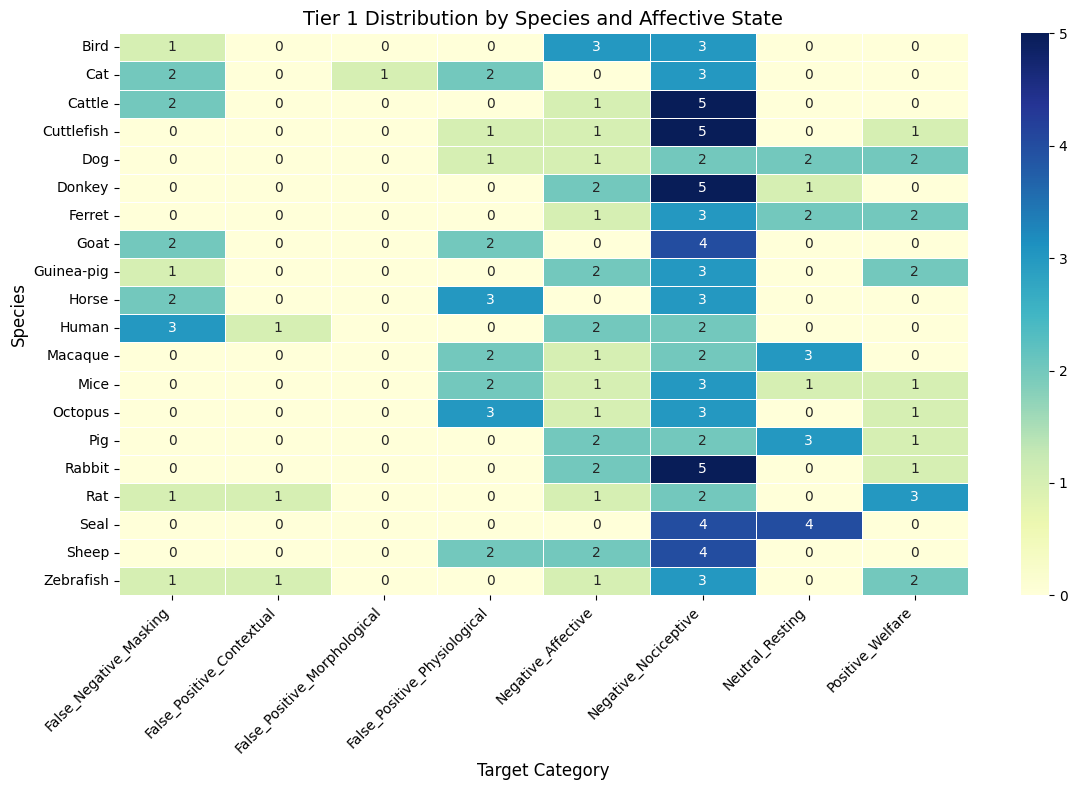


--- SEMANTIC DIVERSITY & EMBEDDINGS (CACHED) ---
Fetching embeddings...
✅ Loaded 101 from cache. Generated 58 new embeddings.
Projecting t-SNE Diversity Map...


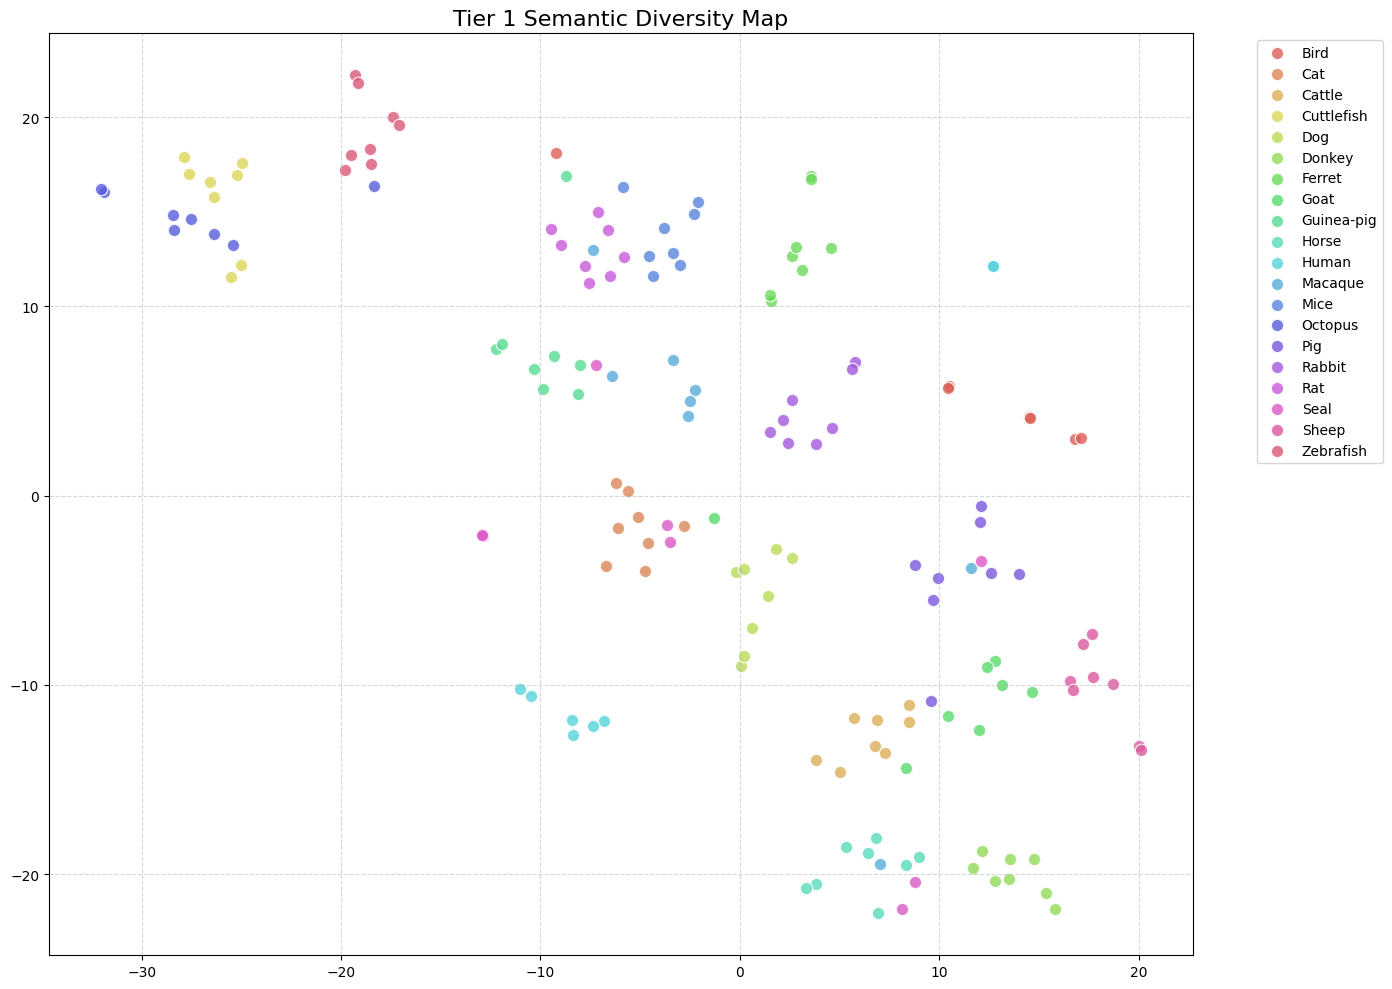


🤖 LLM-READABLE JSON EXPORT (READY FOR TIER 2) 🤖
{
  "tier_1_stats": {
    "total_tasks": 159,
    "semantic_diversity": 0.2179,
    "lexical_richness_ttr": 0.2912,
    "structural_variance_words": 19.13,
    "potential_duplicates_flagged": 79,
    "unique_tasks_remaining": 80
  },
  "category_distribution": {
    "False_Negative_Masking": {
      "Bird": 1,
      "Cat": 2,
      "Cattle": 2,
      "Cuttlefish": 0,
      "Dog": 0,
      "Donkey": 0,
      "Ferret": 0,
      "Goat": 2,
      "Guinea-pig": 1,
      "Horse": 2,
      "Human": 3,
      "Macaque": 0,
      "Mice": 0,
      "Octopus": 0,
      "Pig": 0,
      "Rabbit": 0,
      "Rat": 1,
      "Seal": 0,
      "Sheep": 0,
      "Zebrafish": 1
    },
    "False_Positive_Contextual": {
      "Bird": 0,
      "Cat": 0,
      "Cattle": 0,
      "Cuttlefish": 0,
      "Dog": 0,
      "Donkey": 0,
      "Ferret": 0,
      "Goat": 0,
      "Guinea-pig": 0,
      "Horse": 0,
      "Human": 1,
      "Macaque": 0,
      "Mice": 0,
   

In [ ]:
#@title [CELL 6.1] Tier 1 EDA & Benchmark Diagnostics (Cached)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import collections
import json
import time

# ==========================================
# 0. GLOBAL EMBEDDINGS CACHE
# ==========================================
if 'EMBEDDINGS_CACHE' not in globals():
    EMBEDDINGS_CACHE = {}

CORE_CATEGORIES = [
    "Negative_Nociceptive", "Positive_Welfare", "Neutral_Resting",
    "False_Positive_Morphological", "False_Positive_Physiological",
    "False_Negative_Masking", "False_Positive_Contextual", "Negative_Affective"
]

def normalize_category(raw_label: str) -> str:
    raw = raw_label.lower()
    if any(k in raw for k in ["mask", "freez", "false negative", "inconclusive"]): return "False_Negative_Masking"
    elif any(k in raw for k in ["morphological", "breed"]): return "False_Positive_Morphological"
    elif any(k in raw for k in ["sedat", "anesthe", "physiol", "exhaust", "tired", "hangover", "sleep", "fatigue", "senescence"]): return "False_Positive_Physiological"
    elif any(k in raw for k in ["context", "artifact", "algorithmic"]): return "False_Positive_Contextual"
    elif any(k in raw for k in ["affect", "stress", "fear", "anxiety", "frustration", "agonism"]): return "Negative_Affective"
    elif any(k in raw for k in ["nocicept", "pain", "score 2", "score 3", "score 1"]): return "Negative_Nociceptive"
    elif any(k in raw for k in ["welfare", "joy", "positive", "enrich", "social"]): return "Positive_Welfare"
    elif any(k in raw for k in ["neutral", "rest", "score 0"]): return "Neutral_Resting"
    return "Negative_Nociceptive"

def analyze_categorical_distribution(dataset):
    print("--- CATEGORICAL DISTRIBUTION ---")
    df = pd.DataFrame(dataset)
    df['species_class'] = [t['task_id'].split('_')[2].capitalize() for t in dataset]
    pivot_df = pd.crosstab(df['species_class'], df['target_category'])

    plt.figure(figsize=(12, 8))
    sns.heatmap(pivot_df, annot=True, cmap="YlGnBu", fmt='g', linewidths=.5)
    plt.title("Tier 1 Distribution by Species and Affective State", fontsize=14)
    plt.ylabel("Species", fontsize=12)
    plt.xlabel("Target Category", fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    return pivot_df.to_dict()

def analyze_semantic_diversity_cached(dataset, threshold=0.90):
    print("\n--- SEMANTIC DIVERSITY & EMBEDDINGS (CACHED) ---")

    embeddings = []
    texts = []
    new_embeddings_count = 0
    client = get_client()

    print("Fetching embeddings...")
    for i, t in enumerate(dataset):
        txt = f"{t['context_metadata']} {t['visual_cues']} {t['extracted_medical_rules']}"
        texts.append(txt)
        task_id = t['task_id']

        # Check Cache
        if task_id in EMBEDDINGS_CACHE:
            embeddings.append(EMBEDDINGS_CACHE[task_id])
        else:
            try:
                resp = client.embeddings.create(model="gemini-embedding-2", input=txt)
                vec = resp.data[0].embedding
                EMBEDDINGS_CACHE[task_id] = vec
                embeddings.append(vec)
                new_embeddings_count += 1
            except Exception as e:
                print(f"      [API Error] Retrying embedding for {task_id}...")
                time.sleep(2)
                resp = client.embeddings.create(model="gemini-embedding-2", input=txt)
                vec = resp.data[0].embedding
                EMBEDDINGS_CACHE[task_id] = vec
                embeddings.append(vec)
                new_embeddings_count += 1
            time.sleep(0.1)

    print(f"✅ Loaded {len(dataset) - new_embeddings_count} from cache. Generated {new_embeddings_count} new embeddings.")

    matrix = np.array(embeddings)
    sims = cosine_similarity(matrix)
    upper_tri = sims[np.triu_indices(sims.shape[0], k=1)]
    semantic_diversity = 1.0 - np.mean(upper_tri)

    all_words = " ".join(texts).lower().split()
    ttr = len(set(all_words)) / len(all_words)
    variance = np.std([len(t.split()) for t in texts])

    to_drop = set()
    by_sp = collections.defaultdict(list)
    for idx, t in enumerate(dataset):
        by_sp[t['task_id'].split('_')[2]].append(idx)

    for sp, indices in by_sp.items():
        for i in range(len(indices)):
            if indices[i] in to_drop: continue
            for j in range(i + 1, len(indices)):
                if indices[j] in to_drop: continue
                if sims[indices[i], indices[j]] > threshold: to_drop.add(indices[j])

    potential_drops = len(to_drop)

    print("Projecting t-SNE Diversity Map...")
    pca = PCA(n_components=max(2, min(50, len(dataset)-1)))
    pca_res = pca.fit_transform(matrix)
    vis_dims = TSNE(n_components=2, perplexity=min(15, len(dataset)-1), random_state=42).fit_transform(pca_res)

    df = pd.DataFrame(dataset)
    df['species_class'] = [t['task_id'].split('_')[2].capitalize() for t in dataset]

    plt.figure(figsize=(14, 10))
    classes = sorted(df['species_class'].unique())
    pal = sns.color_palette("hls", len(classes))
    for i, sp in enumerate(classes):
        idx = df[df['species_class'] == sp].index
        plt.scatter(vis_dims[idx, 0], vis_dims[idx, 1], color=pal[i], label=sp, alpha=0.8, edgecolors='w', s=80)

    plt.title('Tier 1 Semantic Diversity Map', fontsize=16)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=1)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    return {
        "total_tasks": len(dataset),
        "semantic_diversity": round(semantic_diversity, 4),
        "lexical_richness_ttr": round(ttr, 4),
        "structural_variance_words": round(variance, 2),
        "potential_duplicates_flagged": potential_drops,
        "unique_tasks_remaining": len(dataset) - potential_drops
    }

if 'tier1_dataset' in locals():
    print(f"Normalizing labels and running diagnostics on {len(tier1_dataset)} tasks...\n")
    for task in tier1_dataset: task['target_category'] = normalize_category(task['target_category'])

    # Save the normalized state!
    import json
    with open("farm_tier1_raw_cleaned.json", "w", encoding="utf-8") as f:
        json.dump(tier1_dataset, f, indent=2)

    heatmap_json = analyze_categorical_distribution(tier1_dataset)
    stats_json = analyze_semantic_diversity_cached(tier1_dataset, threshold=0.90)

    print("\n" + "="*50)
    print("🤖 LLM-READABLE JSON EXPORT (READY FOR TIER 2) 🤖")
    print("="*50)
    print(json.dumps({"tier_1_stats": stats_json, "category_distribution": heatmap_json}, indent=2))
else:
    print("Please run Tier 1 Generation first.")

In [ ]:
#@title [CELL 7] Tier 2: The Category Hunter
import time
import json
import collections

# --- TIER 2 SYSTEM PROMPT ---
TIER2_GENERATOR_PROMPT = """You are an expert veterinary AI data synthesizer.
We are targeting specific missing edge-cases from the {SPECIES} manual.

THE BOUNTY BOARD (Target Categories):
{TARGETS}

AVOID REPEATS (Do NOT use these scenarios, we already have them):
{AVOID_CUES}

INSTRUCTIONS:
1. Scan the manual for facts that naturally map to ANY of the Target Categories.
2. The `adversarial_distractor` must state a TRUE biological rule misapplied to the context.
3. `target_category` MUST be exactly one of our 8 Core Categories.
4. THE FAILSAFE: If the text does NOT contain information supporting the Target Categories, return an EMPTY LIST. Do not hallucinate or stretch the truth to hit quotas. Returning 0 tasks is safe and expected if the manual is thin.

Generate up to {NEEDED} distinct tasks mapping to the Bounty Board.
"""

def get_tier2_targets_and_cues(dataset, species_name, min_quota=2):
    """Identifies which categories need filling and which cues to avoid."""
    sp_tasks = [t for t in dataset if t['task_id'].split('_')[2].lower() == species_name.lower()]

    # What do we already have?
    existing_cats = collections.Counter([t['target_category'] for t in sp_tasks])
    avoid_cues = [t['visual_cues'][:100] + "..." for t in sp_tasks] # Brief snippets to avoid overloading context

    # What do we need?
    targets = [cat for cat in CORE_CATEGORIES if existing_cats.get(cat, 0) < min_quota]
    return targets, avoid_cues

def run_tier2_pipeline(species_name: str, context_text: str, targets: list, avoid_cues: list):
    print(f"\n{'='*60}\n🎯 TIER 2: HUNTING FOR {species_name.upper()}\n{'='*60}")
    print(f"  Targets: {targets}")

    if not targets:
        print("  ✅ Species already has excellent coverage. Skipping.")
        return []

    needed_total = len(targets) * 2 # Aiming for 2 per missing category
    needed_total = min(needed_total, 6) # Cap at 6 to prevent context degradation

    gen_messages = [
        {"role": "system", "content": TIER2_GENERATOR_PROMPT.format(
            SPECIES=species_name.upper(),
            TARGETS=json.dumps(targets),
            AVOID_CUES=json.dumps(avoid_cues, indent=2),
            NEEDED=needed_total
        )},
        {"role": "user", "content": f"Species Context:\n{context_text}"}
    ]

    gen_parsed = safe_api_call(gen_messages, LLM_TaskBatch, temperature=1.0)

    if not gen_parsed or not gen_parsed.tasks:
        print("  ✅ Failsafe Triggered: LLM found no valid rules for these targets. Returned 0.")
        return []

    tasks_dicts = [t.model_dump() for t in gen_parsed.tasks]
    print(f"  [Agent 1] Found {len(tasks_dicts)} targeted tasks.")

    # Agent 2: Auditor (Using the exact same strict logic from Tier 1)
    rev_parsed = safe_api_call([
        {"role": "system", "content": REVIEWER_SYSTEM_PROMPT},
        {"role": "user", "content": f"Species Context:\n{context_text}\n\nAudit tasks:\n{json.dumps(tasks_dicts, indent=2)}"}
    ], ReviewBatch, temperature=1.0)

    passed_review = []
    if rev_parsed:
        flawed_indices = {r.task_index: r.critique for r in rev_parsed.reviews if r.is_flawed}
        for idx, t in enumerate(tasks_dicts):
            if idx not in flawed_indices: passed_review.append(t)
            else: print(f"    ❌ Agent 2 Dropped Task {idx}: {flawed_indices[idx][:60]}...")

    # Agent 3: Citation Validator
    valid_batch = validate_multiple_citations(passed_review, context_text)

    # Final cleanup to ensure LLM respected the Core Categories
    final_batch = []
    for t in valid_batch:
        norm_cat = normalize_category(t['target_category'])
        if norm_cat in targets:
            t['target_category'] = norm_cat
            final_batch.append(t)

    print(f"🎉 Tier 2 Complete for {species_name}: Secured {len(final_batch)} targeted tasks.")
    return final_batch

# --- TIER 2 EXECUTION ---
if 'tier1_dataset' in locals() and 'species_dict' in locals():
    tier2_dataset = list(tier1_dataset) # Start with Tier 1 base

    for species, content in species_dict.items():
        targets, avoid = get_tier2_targets_and_cues(tier2_dataset, species)

        if targets:
            new_tasks = run_tier2_pipeline(species, content, targets, avoid)
            for i, task in enumerate(new_tasks):
                db_task = {
                    "task_id": f"farm_t2_{species.lower()}_{i+1:03d}",
                    "sampling_strategy": "Tier_2_Targeted",
                    **task
                }
                tier2_dataset.append(db_task)

    print("\n" + "="*60 + f"\n🏆 TIER 2 COMPLETE: {len(tier2_dataset)} total tasks secured.\n" + "="*60)
    with open("farm_tier2_raw.json", "w", encoding="utf-8") as f:
        json.dump(tier2_dataset, f, indent=2)
else:
    print("Please run Tier 1 first.")


🎯 TIER 2: HUNTING FOR BIRD
  Targets: ['Positive_Welfare', 'Neutral_Resting', 'False_Positive_Morphological', 'False_Positive_Physiological', 'False_Negative_Masking', 'False_Positive_Contextual']
  [Agent 1] Found 6 targeted tasks.
🎉 Tier 2 Complete for Bird: Secured 6 targeted tasks.

🎯 TIER 2: HUNTING FOR CAT
  Targets: ['Positive_Welfare', 'Neutral_Resting', 'False_Positive_Morphological', 'False_Positive_Contextual', 'Negative_Affective']
  [Agent 1] Found 6 targeted tasks.
🎉 Tier 2 Complete for Cat: Secured 6 targeted tasks.

🎯 TIER 2: HUNTING FOR CATTLE
  Targets: ['Positive_Welfare', 'Neutral_Resting', 'False_Positive_Morphological', 'False_Positive_Physiological', 'False_Positive_Contextual', 'Negative_Affective']
  [Agent 1] Found 6 targeted tasks.
🎉 Tier 2 Complete for Cattle: Secured 6 targeted tasks.

🎯 TIER 2: HUNTING FOR CUTTLEFISH
  Targets: ['Positive_Welfare', 'Neutral_Resting', 'False_Positive_Morphological', 'False_Positive_Physiological', 'False_Negative_Masking',

Running diagnostics on 253 tasks...

--- CATEGORICAL DISTRIBUTION (TIER 1 + TIER 2) ---


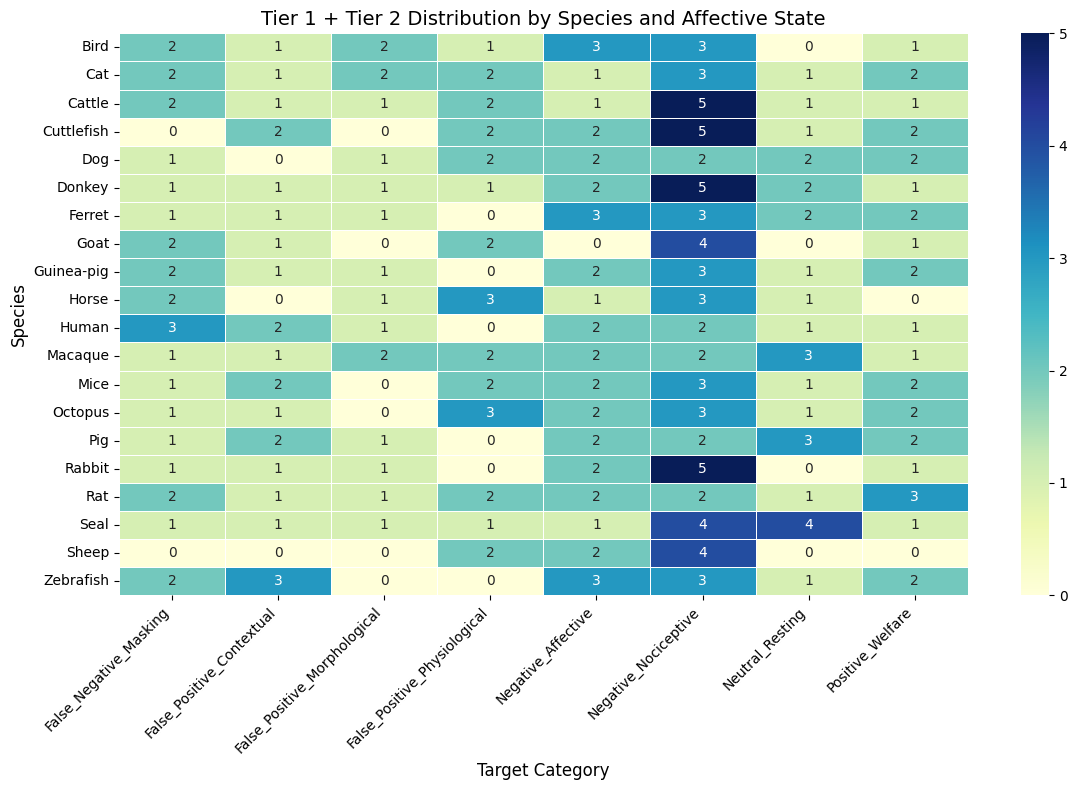


--- SEMANTIC DIVERSITY & EMBEDDINGS (CACHED) ---
Fetching embeddings (Reusing cached vectors for efficiency)...
✅ Loaded 159 from cache. Generated 94 new embeddings.
Projecting t-SNE Diversity Map...


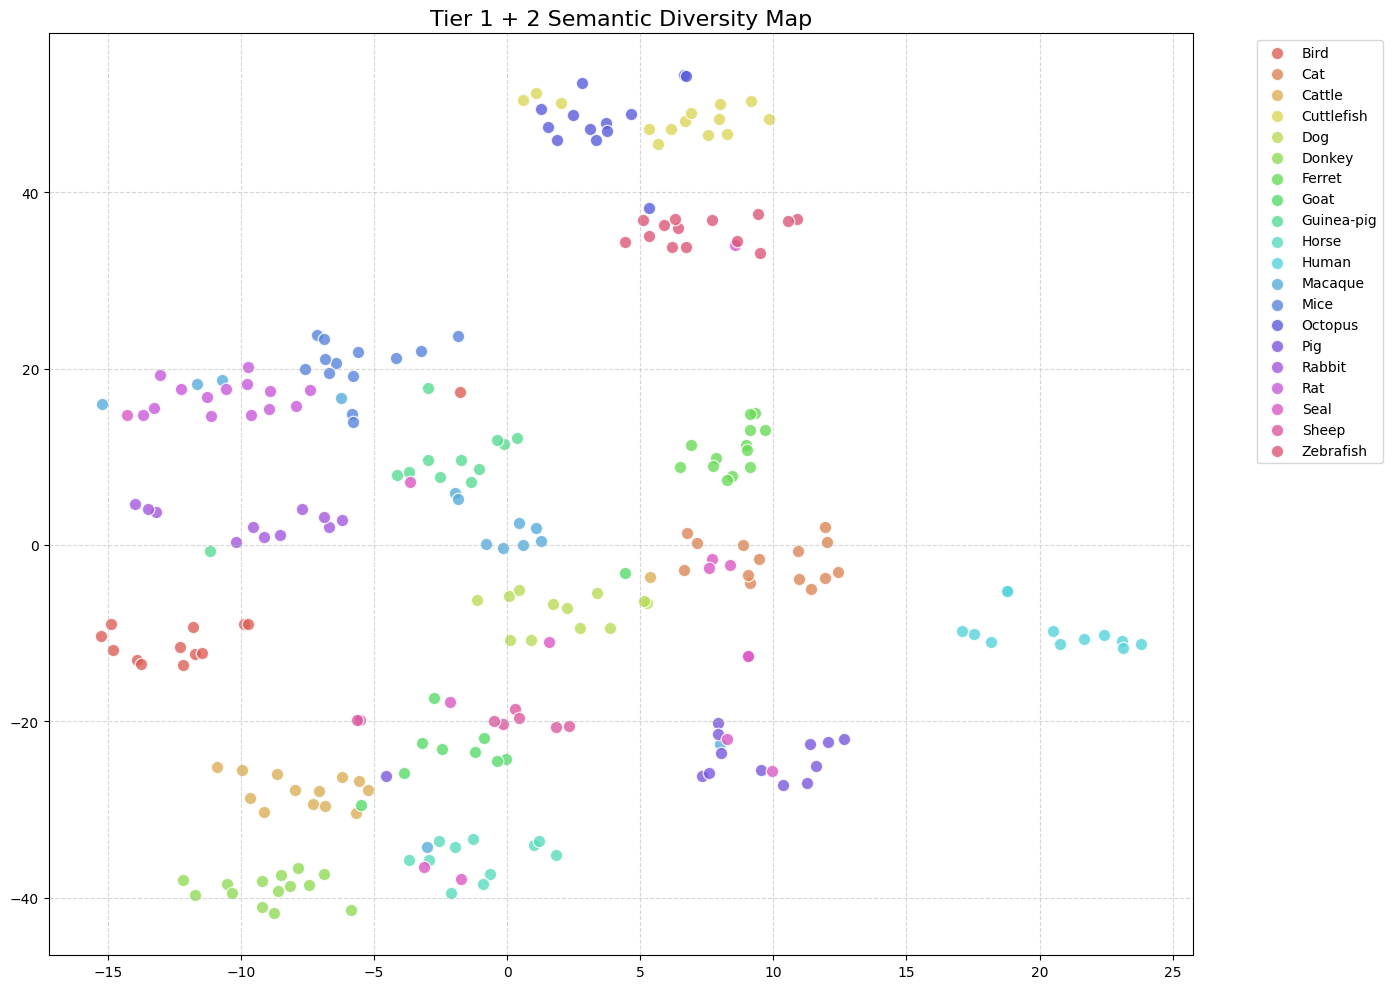


🤖 LLM-READABLE JSON EXPORT (READY FOR TIER 3) 🤖
{
  "tier_2_stats": {
    "total_tasks": 253,
    "semantic_diversity": 0.2442,
    "lexical_richness_ttr": 0.2513,
    "structural_variance_words": 17.49,
    "potential_duplicates_flagged": 118,
    "unique_tasks_remaining": 135
  },
  "category_distribution": {
    "False_Negative_Masking": {
      "Bird": 2,
      "Cat": 2,
      "Cattle": 2,
      "Cuttlefish": 0,
      "Dog": 1,
      "Donkey": 1,
      "Ferret": 1,
      "Goat": 2,
      "Guinea-pig": 2,
      "Horse": 2,
      "Human": 3,
      "Macaque": 1,
      "Mice": 1,
      "Octopus": 1,
      "Pig": 1,
      "Rabbit": 1,
      "Rat": 2,
      "Seal": 1,
      "Sheep": 0,
      "Zebrafish": 2
    },
    "False_Positive_Contextual": {
      "Bird": 1,
      "Cat": 1,
      "Cattle": 1,
      "Cuttlefish": 2,
      "Dog": 0,
      "Donkey": 1,
      "Ferret": 1,
      "Goat": 1,
      "Guinea-pig": 1,
      "Horse": 0,
      "Human": 2,
      "Macaque": 1,
      "Mice": 2,
 

In [ ]:
#@title [CELL 7.1] Tier 2 EDA: Heatmap & Cached Embeddings Map
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import collections
import json
import time

# Initialize global cache if it doesn't exist
if 'EMBEDDINGS_CACHE' not in globals():
    EMBEDDINGS_CACHE = {}

def analyze_categorical_distribution_t2(dataset):
    print("--- CATEGORICAL DISTRIBUTION (TIER 1 + TIER 2) ---")
    df = pd.DataFrame(dataset)
    df['species_class'] = [t['task_id'].split('_')[2].capitalize() for t in dataset]
    pivot_df = pd.crosstab(df['species_class'], df['target_category'])

    plt.figure(figsize=(12, 8))
    sns.heatmap(pivot_df, annot=True, cmap="YlGnBu", fmt='g', linewidths=.5)
    plt.title("Tier 1 + Tier 2 Distribution by Species and Affective State", fontsize=14)
    plt.ylabel("Species", fontsize=12)
    plt.xlabel("Target Category", fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    return pivot_df.to_dict()

def analyze_semantic_diversity_cached(dataset, threshold=0.90):
    print("\n--- SEMANTIC DIVERSITY & EMBEDDINGS (CACHED) ---")

    embeddings = []
    texts = []
    new_embeddings_count = 0
    client = get_client()

    print("Fetching embeddings (Reusing cached vectors for efficiency)...")
    for i, t in enumerate(dataset):
        txt = f"{t['context_metadata']} {t['visual_cues']} {t['extracted_medical_rules']}"
        texts.append(txt)
        task_id = t['task_id']

        # Check cache first!
        if task_id in EMBEDDINGS_CACHE:
            embeddings.append(EMBEDDINGS_CACHE[task_id])
        else:
            # Not in cache, ping API
            try:
                resp = client.embeddings.create(model="gemini-embedding-2", input=txt)
                vec = resp.data[0].embedding
                EMBEDDINGS_CACHE[task_id] = vec
                embeddings.append(vec)
                new_embeddings_count += 1
            except Exception as e:
                print(f"      [API Error] Retrying embedding for {task_id}...")
                time.sleep(2)
                resp = client.embeddings.create(model="gemini-embedding-2", input=txt)
                vec = resp.data[0].embedding
                EMBEDDINGS_CACHE[task_id] = vec
                embeddings.append(vec)
                new_embeddings_count += 1
            time.sleep(0.1) # Micro-sleep

    print(f"✅ Loaded {len(dataset) - new_embeddings_count} from cache. Generated {new_embeddings_count} new embeddings.")

    matrix = np.array(embeddings)
    sims = cosine_similarity(matrix)
    upper_tri = sims[np.triu_indices(sims.shape[0], k=1)]
    semantic_diversity = 1.0 - np.mean(upper_tri)

    all_words = " ".join(texts).lower().split()
    ttr = len(set(all_words)) / len(all_words)
    variance = np.std([len(t.split()) for t in texts])

    to_drop = set()
    by_sp = collections.defaultdict(list)
    for idx, t in enumerate(dataset):
        by_sp[t['task_id'].split('_')[2]].append(idx)

    for sp, indices in by_sp.items():
        for i in range(len(indices)):
            if indices[i] in to_drop: continue
            for j in range(i + 1, len(indices)):
                if indices[j] in to_drop: continue
                if sims[indices[i], indices[j]] > threshold: to_drop.add(indices[j])

    potential_drops = len(to_drop)

    print("Projecting t-SNE Diversity Map...")
    pca = PCA(n_components=max(2, min(50, len(dataset)-1)))
    pca_res = pca.fit_transform(matrix)
    vis_dims = TSNE(n_components=2, perplexity=min(15, len(dataset)-1), random_state=42).fit_transform(pca_res)

    df = pd.DataFrame(dataset)
    df['species_class'] = [t['task_id'].split('_')[2].capitalize() for t in dataset]

    plt.figure(figsize=(14, 10))
    classes = sorted(df['species_class'].unique())
    pal = sns.color_palette("hls", len(classes))
    for i, sp in enumerate(classes):
        idx = df[df['species_class'] == sp].index
        plt.scatter(vis_dims[idx, 0], vis_dims[idx, 1], color=pal[i], label=sp, alpha=0.8, edgecolors='w', s=80)

    plt.title('Tier 1 + 2 Semantic Diversity Map', fontsize=16)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=1)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    return {
        "total_tasks": len(dataset),
        "semantic_diversity": round(semantic_diversity, 4),
        "lexical_richness_ttr": round(ttr, 4),
        "structural_variance_words": round(variance, 2),
        "potential_duplicates_flagged": potential_drops,
        "unique_tasks_remaining": len(dataset) - potential_drops
    }

# --- EXECUTION ---
if 'tier2_dataset' in locals():
    print(f"Running diagnostics on {len(tier2_dataset)} tasks...\n")

    # 1. Heatmap
    heatmap_json = analyze_categorical_distribution_t2(tier2_dataset)

    # 2. Embeddings & Stats
    stats_json = analyze_semantic_diversity_cached(tier2_dataset, threshold=0.90)

    # 3. Output for the AI
    print("\n" + "="*50)
    print("🤖 LLM-READABLE JSON EXPORT (READY FOR TIER 3) 🤖")
    print("="*50)
    print(json.dumps({"tier_2_stats": stats_json, "category_distribution": heatmap_json}, indent=2))
else:
    print("Please run Tier 2 Generation first to populate 'tier2_dataset'.")

In [ ]:
#@title [CELL 8] Tier 3: Cross-Species Paradoxes (The Battle Arenas)
import time
import json
import collections

# ==========================================
# ⚔️ THE BATTLE ARENAS
# ==========================================
ARENAS = {
    "Muzzle_Topology_Paradox": ["Mice", "Rat", "Ferret", "Rabbit"],
    "Orbital_Aperture_Reversal": ["Pig", "Goat", "Cat"],
    "Equid_Kinematic_Divergence": ["Horse", "Donkey", "Cattle"],
    "Auricular_Morphology_Blindspot": ["Seal", "Rabbit", "Dog"],
    "Primate_Anthropomorphism": ["Human", "Macaque", "Dog"],
    "Invertebrate_FACS_Failure": ["Human", "Octopus", "Cuttlefish"],
    "Prey_Conservation_Withdrawal": ["Guinea-pig", "Bird", "Sheep"],
    "Aquatic_Spatial_Anomalies": ["Zebrafish", "Cuttlefish"]
}

# --- TIER 3 SYSTEM PROMPT ---
TIER3_GENERATOR_PROMPT = """You are an elite veterinary AI synthesizing cross-species diagnostic traps.
You are provided with multiple species manuals at once.

YOUR MISSION:
Create tasks where a 100% true biological rule from Species A is used as a deadly Red Herring trap for Species B.

EXAMPLE LOGIC (Do not copy):
- Subject: Rat
- Trap Rule (from Mouse manual): "The Mouse Grimace Scale identifies a nose/cheek bulge as a sign of pain."
- Trap Distractor: "Because standard rodent grimace scales use nose bulging to identify nociception, the lack of a bulge in this rat means it is pain-free."
- SOTA Reasoning: "This applies a Mouse rule to a Rat. In Rats, pain is actually indicated by nose flattening, not bulging."

CRITICAL RULES:
1. `target_subject_species`: Must be exactly ONE of the species provided.
2. `referenced_manuals`: Must list the manuals you used (e.g., ["Mice", "Rat"]).
3. `extracted_medical_rules`: Quote the true rule from the WRONG species (Species A).
4. `adversarial_distractor`: Present the Species A rule as a trap for Species B.
5. NO FAKE BIOLOGY. The rule must be a verbatim truth from the provided texts.

Generate up to 8 distinct Cross-Species tasks for this Arena.
"""

def run_tier3_pipeline(arena_name: str, species_list: list, species_dict: dict, target_quota: int = 8):
    print(f"\n{'='*60}\n⚔️ TIER 3 ARENA: {arena_name.upper()} {species_list}\n{'='*60}")

    # 1. Combine the contexts for the Arena
    combined_context = ""
    for sp in species_list:
        combined_context += f"\n\n--- {sp.upper()} MANUAL ---\n"
        combined_context += species_dict.get(sp, "")

    all_valid_tasks = []
    seen_traps = set()
    attempts = 0
    batch_size = 6
    max_attempts = (target_quota // batch_size) + 3

    while len(all_valid_tasks) < target_quota and attempts < max_attempts:
        attempts += 1
        needed = min(batch_size, target_quota - len(all_valid_tasks))
        print(f"\n  ▶️ [Attempt {attempts}/{max_attempts}] Requesting {needed} cross-species tasks...")

        # --- AGENT 1: GENERATE ---
        gen_parsed = safe_api_call([
            {"role": "system", "content": TIER3_GENERATOR_PROMPT},
            {"role": "user", "content": f"COMBINED ARENA CONTEXT:\n{combined_context}\n\nGenerate exactly {needed} unique Cross-Species tasks."}
        ], LLM_TaskBatch, temperature=1.0)

        if not gen_parsed or not gen_parsed.tasks:
            print("    ⚠️ Agent 1 returned no tasks.")
            continue

        tasks_dicts = [t.model_dump() for t in gen_parsed.tasks]

        # --- AGENT 2: AUDITOR ---
        print("    ▶️ [Agent 2] Auditing cross-species logic...")
        rev_parsed = safe_api_call([
            {"role": "system", "content": REVIEWER_SYSTEM_PROMPT},
            {"role": "user", "content": f"COMBINED ARENA CONTEXT:\n{combined_context}\n\nAudit tasks:\n{json.dumps(tasks_dicts, indent=2)}"}
        ], ReviewBatch, temperature=1.0)

        passed_review = []
        if rev_parsed:
            flawed_indices = {r.task_index: r.critique for r in rev_parsed.reviews if r.is_flawed}
            for idx, t in enumerate(tasks_dicts):
                if idx in flawed_indices:
                    print(f"      ❌ Dropped Task {idx}: {flawed_indices[idx][:60]}...")
                else:
                    passed_review.append(t)

        # --- AGENT 3: CITATION CHECKER ---
        print("    ▶️ [Agent 3] Validating Citations against combined context...")
        valid_batch = validate_multiple_citations(passed_review, combined_context)

        for v_task in valid_batch:
            sig = v_task['adversarial_distractor'][:50].lower()
            if sig not in seen_traps:
                seen_traps.add(sig)
                all_valid_tasks.append(v_task)

        print(f"    ✅ Arena survivors added this round. Total in vault: {len(all_valid_tasks)}/{target_quota}")
        if len(all_valid_tasks) >= target_quota: break

    return all_valid_tasks

# --- TIER 3 EXECUTION ---
if 'tier2_dataset' in locals() and 'species_dict' in locals():
    tier3_dataset = list(tier2_dataset) # Copy the base of 253 tasks

    for arena_name, species_list in ARENAS.items():
        # Double check we actually have the manuals
        valid_species = [s for s in species_list if s in species_dict]
        if len(valid_species) < 2:
            print(f"Skipping {arena_name}, not enough manuals found.")
            continue

        arena_tasks = run_tier3_pipeline(arena_name, valid_species, species_dict, target_quota=8)

        for i, task in enumerate(arena_tasks):
            db_task = {
                "task_id": f"farm_t3_{arena_name.lower()}_{i+1:03d}",
                "sampling_strategy": "Tier_3_Cross_Species",
                **task
            }
            tier3_dataset.append(db_task)

    print("\n" + "="*60 + f"\n🏆 TIER 3 COMPLETE: {len(tier3_dataset)} total benchmark tasks secured.\n" + "="*60)

    # Save the absolute final raw dataset
    with open("farm_tier3_raw_final.json", "w", encoding="utf-8") as f:
        json.dump(tier3_dataset, f, indent=2)
else:
    print("Please ensure Tier 2 has finished and 'tier2_dataset' exists.")


⚔️ TIER 3 ARENA: MUZZLE_TOPOLOGY_PARADOX ['Mice', 'Rat', 'Ferret', 'Rabbit']

  ▶️ [Attempt 1/4] Requesting 6 cross-species tasks...
    ⚠️ Agent 1 returned no tasks.

  ▶️ [Attempt 2/4] Requesting 6 cross-species tasks...
    ▶️ [Agent 2] Auditing cross-species logic...
    ▶️ [Agent 3] Validating Citations against combined context...
    ✅ Arena survivors added this round. Total in vault: 6/8

  ▶️ [Attempt 3/4] Requesting 2 cross-species tasks...
    ▶️ [Agent 2] Auditing cross-species logic...
    ▶️ [Agent 3] Validating Citations against combined context...
    ✅ Arena survivors added this round. Total in vault: 8/8

⚔️ TIER 3 ARENA: ORBITAL_APERTURE_REVERSAL ['Pig', 'Goat', 'Cat']

  ▶️ [Attempt 1/4] Requesting 6 cross-species tasks...
    ▶️ [Agent 2] Auditing cross-species logic...
    ▶️ [Agent 3] Validating Citations against combined context...
    ✅ Arena survivors added this round. Total in vault: 6/8

  ▶️ [Attempt 2/4] Requesting 2 cross-species tasks...
    ⚠️ Agent 1 r

✅ Harmonized 313 tasks into 20 Parent Classes and 8 Core Categories.


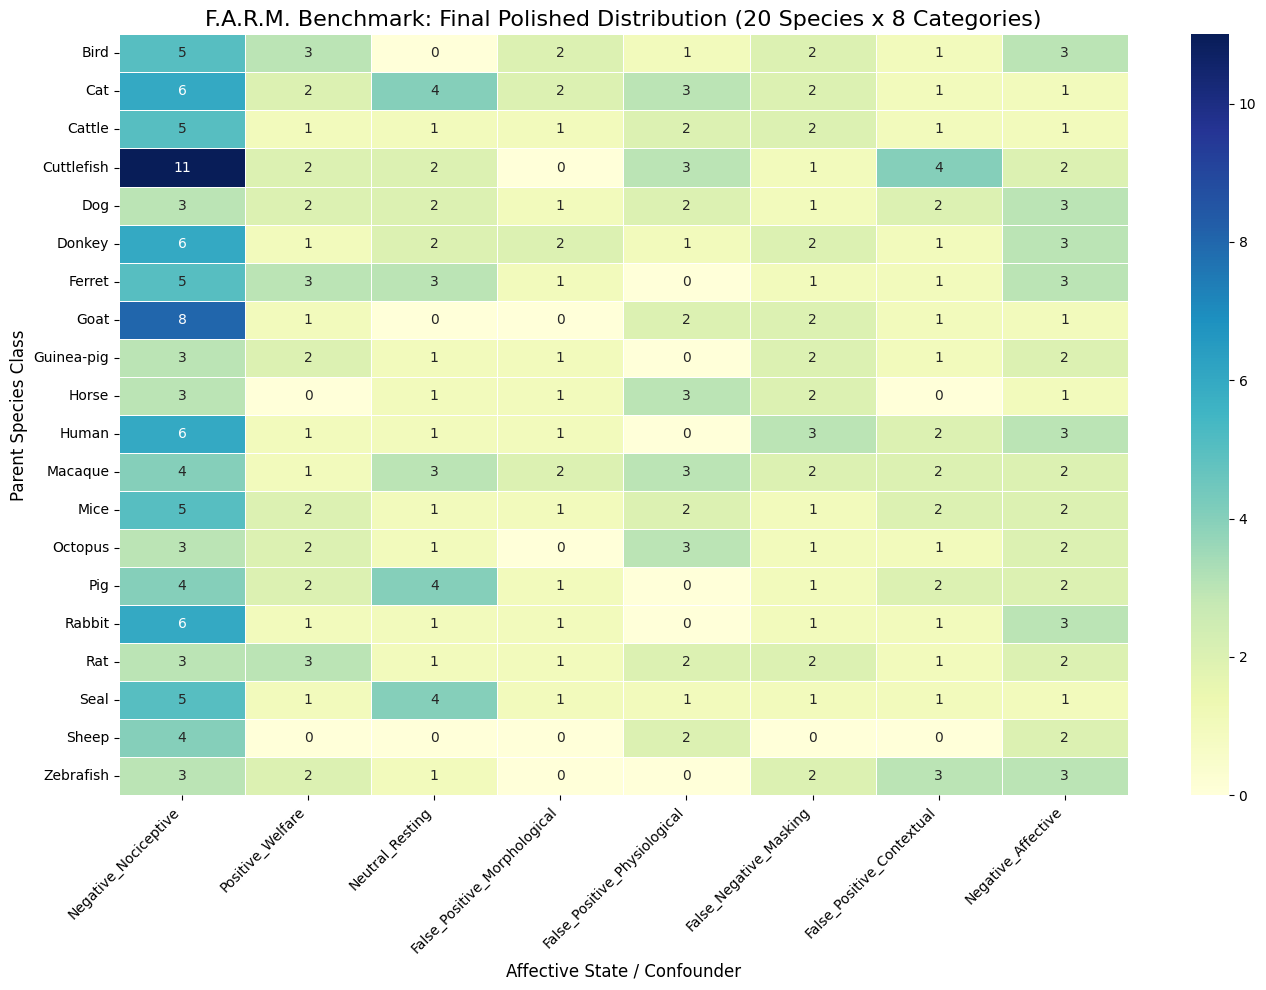


Calculating Final Diversity Stats...
🏆 FINAL SEMANTIC DIVERSITY: 0.2448


In [ ]:
#@title [CELL 9] The Final Benchmark Harmonizer
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import json
import numpy as np

# 1. THE 20 CANONICAL SPECIES (Parent Classes)
CANONICAL_SPECIES = [
    "Bird", "Cat", "Cattle", "Cuttlefish", "Dog", "Donkey", "Ferret", "Goat",
    "Guinea-pig", "Horse", "Human", "Macaque", "Mice", "Octopus", "Pig",
    "Rabbit", "Rat", "Seal", "Sheep", "Zebrafish"
]

# 2. THE 8 CANONICAL CATEGORIES (Affective States)
CORE_CATEGORIES = [
    "Negative_Nociceptive", "Positive_Welfare", "Neutral_Resting",
    "False_Positive_Morphological", "False_Positive_Physiological",
    "False_Negative_Masking", "False_Positive_Contextual", "Negative_Affective"
]

def harmonize_species(task):
    """Maps specific subjects (Frizzle, Sepia, Harbor) back to the 20 Parent Classes."""
    # Strategy A: Check the task_id (Tier 1 and 2 encode the parent class here)
    for sp in CANONICAL_SPECIES:
        if f"_{sp.lower()}_" in task['task_id'].lower():
            return sp

    # Strategy B: Check the subject name or manual reference
    subject_text = str(task.get('target_subject_species', "")).lower()
    manuals_text = str(task.get('referenced_manuals', [])).lower()

    mapping = {
        "pigeon": "Bird", "chicken": "Bird", "frizzle": "Bird", "columba": "Bird",
        "harbor": "Seal", "phoca": "Seal",
        "sepia": "Cuttlefish",
        "macaque": "Macaque", "rhesus": "Macaque",
        "angus": "Cattle", "holstein": "Cattle", "cow": "Cattle", "calf": "Cattle",
        "sow": "Pig", "piglet": "Pig",
        "beagle": "Dog", "bulldog": "Dog", "hound": "Dog"
    }

    for key, val in mapping.items():
        if key in subject_text or key in manuals_text:
            return val

    # Fallback: Just try to find the word in the string
    for sp in CANONICAL_SPECIES:
        if sp.lower() in subject_text or sp.lower() in manuals_text:
            return sp

    return "Other"

def normalize_category(raw_label: str) -> str:
    raw = str(raw_label).lower()
    if any(k in raw for k in ["mask", "freez", "false negative", "inconclusive"]): return "False_Negative_Masking"
    elif any(k in raw for k in ["morphological", "breed", "skin folding", "frizzle"]): return "False_Positive_Morphological"
    elif any(k in raw for k in ["sedat", "anesthe", "physiol", "exhaust", "tired", "hangover", "sleep", "fatigue", "senescence"]): return "False_Positive_Physiological"
    elif any(k in raw for k in ["context", "artifact", "algorithmic", "observer", "light"]): return "False_Positive_Contextual"
    elif any(k in raw for k in ["affect", "stress", "fear", "anxiety", "frustration", "agonism", "stress"]): return "Negative_Affective"
    elif any(k in raw for k in ["nocicept", "pain", "score 2", "score 3", "score 1", "fracture"]): return "Negative_Nociceptive"
    elif any(k in raw for k in ["welfare", "joy", "positive", "enrich", "social", "tickling", "allogroom"]): return "Positive_Welfare"
    elif any(k in raw for k in ["neutral", "rest", "score 0"]): return "Neutral_Resting"
    return "Negative_Nociceptive"

# --- EXECUTE HARMONIZATION ---
with open("farm_tier3_raw_final.json", "r", encoding="utf-8") as f:
    final_raw = json.load(f)

harmonized_dataset = []
for task in final_raw:
    task['species_class'] = harmonize_species(task)
    task['target_category'] = normalize_category(task['target_category'])
    harmonized_dataset.append(task)

# Save the polished version
with open("farm_gold_standard_harmonized.json", "w", encoding="utf-8") as f:
    json.dump(harmonized_dataset, f, indent=2)

print(f"✅ Harmonized {len(harmonized_dataset)} tasks into 20 Parent Classes and 8 Core Categories.")

# --- FINAL HEATMAP ---
df = pd.DataFrame(harmonized_dataset)
# Filter out "Other" if any survived (should be 0)
df = df[df['species_class'] != "Other"]

plt.figure(figsize=(14, 10))
pivot_df = pd.crosstab(df['species_class'], df['target_category'])
# Ensure all 8 categories are shown, even if 0
for cat in CORE_CATEGORIES:
    if cat not in pivot_df.columns: pivot_df[cat] = 0
pivot_df = pivot_df[CORE_CATEGORIES] # Reorder

sns.heatmap(pivot_df, annot=True, cmap="YlGnBu", fmt='g', linewidths=.5)
plt.title("F.A.R.M. Benchmark: Final Polished Distribution (20 Species x 8 Categories)", fontsize=16)
plt.ylabel("Parent Species Class", fontsize=12)
plt.xlabel("Affective State / Confounder", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# --- FINAL DIVERSITY STATS ---
from sklearn.metrics.pairwise import cosine_similarity
print("\nCalculating Final Diversity Stats...")
# Use global cache if available
embeddings = []
for t in harmonized_dataset:
    if t['task_id'] in EMBEDDINGS_CACHE: embeddings.append(EMBEDDINGS_CACHE[t['task_id']])

if embeddings:
    matrix = np.array(embeddings)
    sims = cosine_similarity(matrix)
    upper_tri = sims[np.triu_indices(sims.shape[0], k=1)]
    print(f"🏆 FINAL SEMANTIC DIVERSITY: {1.0 - np.mean(upper_tri):.4f}")

In [ ]:
#@title [CELL 9.5] Pre-Publication Audit: Split Representative Analysis
import pandas as pd
import collections
import random
import json

# Load harmonized data
with open("farm_gold_standard_harmonized.json", "r", encoding="utf-8") as f:
    dataset = json.load(f)

df = pd.DataFrame(dataset)

# 1. ANALYZE CITATION GROUPS
# We group by the first citation (the primary medical rule)
df['primary_citation'] = df['source_citations'].apply(lambda x: x[0] if isinstance(x, list) and len(x) > 0 else "Unknown")
citation_groups = df.groupby('primary_citation').size().sort_values(ascending=False)

print("--- CITATION GROUPING STATS ---")
print(f"Total Unique Citations: {len(citation_groups)}")
print(f"Avg Tasks per Citation: {citation_groups.mean():.2f}")
print(f"Max Tasks tied to one Citation: {citation_groups.max()} (Group: {citation_groups.index[0][:40]}...)")

# 2. SIMULATE THE SPLIT (Anti-Leakage)
def simulate_split(data, test_ratio=0.15):
    random.seed(42)
    citations = list(df['primary_citation'].unique())
    random.shuffle(citations)

    test_citations = []
    current_test_count = 0
    target_test_count = len(data) * test_ratio

    for cit in citations:
        count = len(df[df['primary_citation'] == cit])
        if current_test_count < target_test_count:
            test_citations.append(cit)
            current_test_count += count

    train_df = df[~df['primary_citation'].isin(test_citations)]
    test_df = df[df['primary_citation'].isin(test_citations)]
    return train_df, test_df

train_set, test_set = simulate_split(df)

# 3. ANALYZE REPRESENTATIVENESS
print("\n" + "="*50)
print("📊 SPLIT REPRESENTATIVE AUDIT 📊")
print("="*50)
print(f"Train Set: {len(train_set)} tasks")
print(f"Test Set:  {len(test_set)} tasks")

# Species Coverage
train_species = set(train_set['species_class'].unique())
test_species = set(test_set['species_class'].unique())
missing_sp = set(CANONICAL_SPECIES) - test_species

print(f"\nSpecies Coverage in Test Set: {len(test_species)}/20")
if missing_sp: print(f"⚠️ Species missing from Test Set: {missing_sp}")

# Category Coverage
train_cats = set(train_set['target_category'].unique())
test_cats = set(test_set['target_category'].unique())
missing_cat = set(CORE_CATEGORIES) - test_cats

print(f"Category Coverage in Test Set: {len(test_cats)}/8")
if missing_cat: print(f"⚠️ Categories missing from Test Set: {missing_cat}")

# Strategy Mix in Test Set
strat_mix = test_set['sampling_strategy'].value_counts()
print("\nStrategy Mix in Test Set (Diversity of Logic):")
for strat, count in strat_mix.items():
    print(f" - {strat}: {count} tasks")

# 4. EXPORT PREVIEW FOR THE AI (You)
audit_report = {
    "split_stats": {
        "train_size": len(train_set),
        "test_size": len(test_set),
        "test_species_count": len(test_species),
        "test_category_count": len(test_cats)
    },
    "test_set_strategy_mix": strat_mix.to_dict(),
    "species_missing_from_test": list(missing_sp)
}
print("\n" + "="*50)
print("🤖 LLM-READABLE AUDIT REPORT 🤖")
print("="*50)
print(json.dumps(audit_report, indent=2))

--- CITATION GROUPING STATS ---
Total Unique Citations: 242
Avg Tasks per Citation: 1.29
Max Tasks tied to one Citation: 4 (Group: [@reijgwart-2017; q="The eyelids close (...)

📊 SPLIT REPRESENTATIVE AUDIT 📊
Train Set: 265 tasks
Test Set:  48 tasks

Species Coverage in Test Set: 17/20
⚠️ Species missing from Test Set: {'Octopus', 'Guinea-pig', 'Cattle'}
Category Coverage in Test Set: 8/8

Strategy Mix in Test Set (Diversity of Logic):
 - Tier_1_Exhaustive: 25 tasks
 - Tier_2_Targeted: 14 tasks
 - Tier_3_Cross_Species: 9 tasks

🤖 LLM-READABLE AUDIT REPORT 🤖
{
  "split_stats": {
    "train_size": 265,
    "test_size": 48,
    "test_species_count": 17,
    "test_category_count": 8
  },
  "test_set_strategy_mix": {
    "Tier_1_Exhaustive": 25,
    "Tier_2_Targeted": 14,
    "Tier_3_Cross_Species": 9
  },
  "species_missing_from_test": [
    "Octopus",
    "Guinea-pig",
    "Cattle"
  ]
}


In [ ]:
#@title [CELL 9.6] Optimal Split Search (Phylogenetic Balancing)
import random

def find_optimal_split(df, target_test_ratio=0.15, max_seeds=200):
    citations = list(df['primary_citation'].unique())
    target_test_count = len(df) * target_test_ratio

    best_seed = -1
    best_species_count = 0
    final_test_df = None
    final_train_df = None

    print(f"Searching for optimal seed to maximize species coverage...")

    for seed in range(max_seeds):
        random.seed(seed)
        shuffled_citations = list(citations)
        random.shuffle(shuffled_citations)

        test_citations = []
        current_test_count = 0
        for cit in shuffled_citations:
            count = len(df[df['primary_citation'] == cit])
            if current_test_count < target_test_count:
                test_citations.append(cit)
                current_test_count += count

        temp_test = df[df['primary_citation'].isin(test_citations)]
        species_in_test = temp_test['species_class'].nunique()
        categories_in_test = temp_test['target_category'].nunique()

        # We want all 20 species and all 8 categories
        if species_in_test > best_species_count and categories_in_test == 8:
            best_species_count = species_in_test
            best_seed = seed
            final_test_df = temp_test
            final_train_df = df[~df['primary_citation'].isin(test_citations)]

            if best_species_count == 20: # Found the holy grail
                break

    print(f"\n✅ Optimal Seed Found: {best_seed}")
    print(f"✅ Species represented in Test: {best_species_count}/20")
    return final_train_df, final_test_df, best_seed

# Run the search
train_set, test_set, final_seed = find_optimal_split(df)

# Final Representative Audit
print("\n" + "="*50)
print(f"📊 FINAL AUDIT (Seed {final_seed}) 📊")
print("="*50)
print(f"Train Set: {len(train_set)} tasks")
print(f"Test Set:  {len(test_set)} tasks")
print(f"Species in Test: {sorted(list(test_set['species_class'].unique()))}")
print(f"\nStrategy Mix in Test Set:")
print(test_set['sampling_strategy'].value_counts())

Searching for optimal seed to maximize species coverage...

✅ Optimal Seed Found: 46
✅ Species represented in Test: 20/20

📊 FINAL AUDIT (Seed 46) 📊
Train Set: 265 tasks
Test Set:  48 tasks
Species in Test: ['Bird', 'Cat', 'Cattle', 'Cuttlefish', 'Dog', 'Donkey', 'Ferret', 'Goat', 'Guinea-pig', 'Horse', 'Human', 'Macaque', 'Mice', 'Octopus', 'Pig', 'Rabbit', 'Rat', 'Seal', 'Sheep', 'Zebrafish']

Strategy Mix in Test Set:
sampling_strategy
Tier_1_Exhaustive       29
Tier_2_Targeted         12
Tier_3_Cross_Species     7
Name: count, dtype: int64


/tmp/ipykernel_11403/2196703438.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_set['split'] = 'Train'
/tmp/ipykernel_11403/2196703438.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_set['split'] = 'Test'


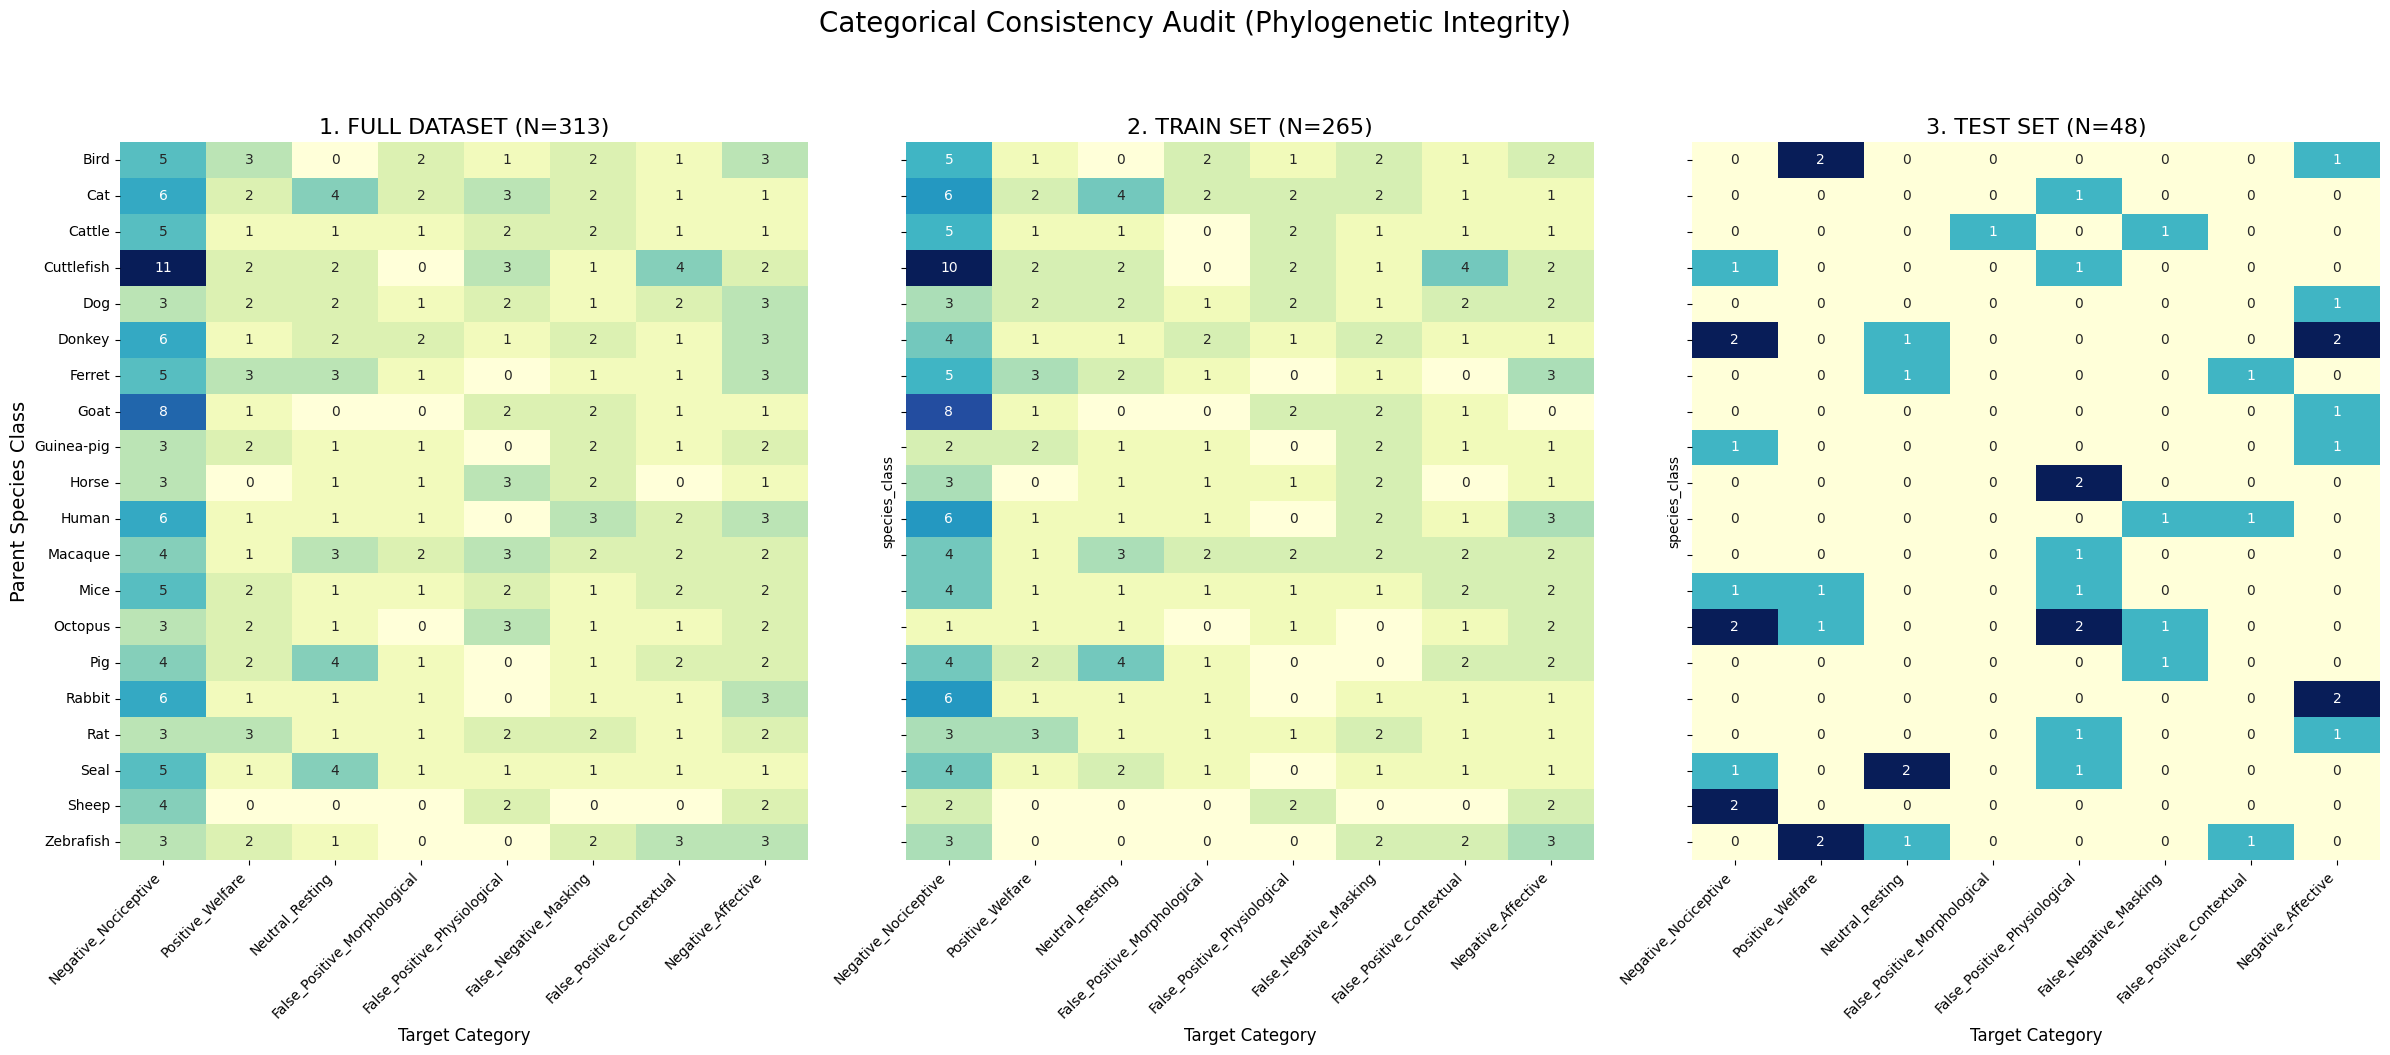


Projecting Final Semantic Overlap Map...


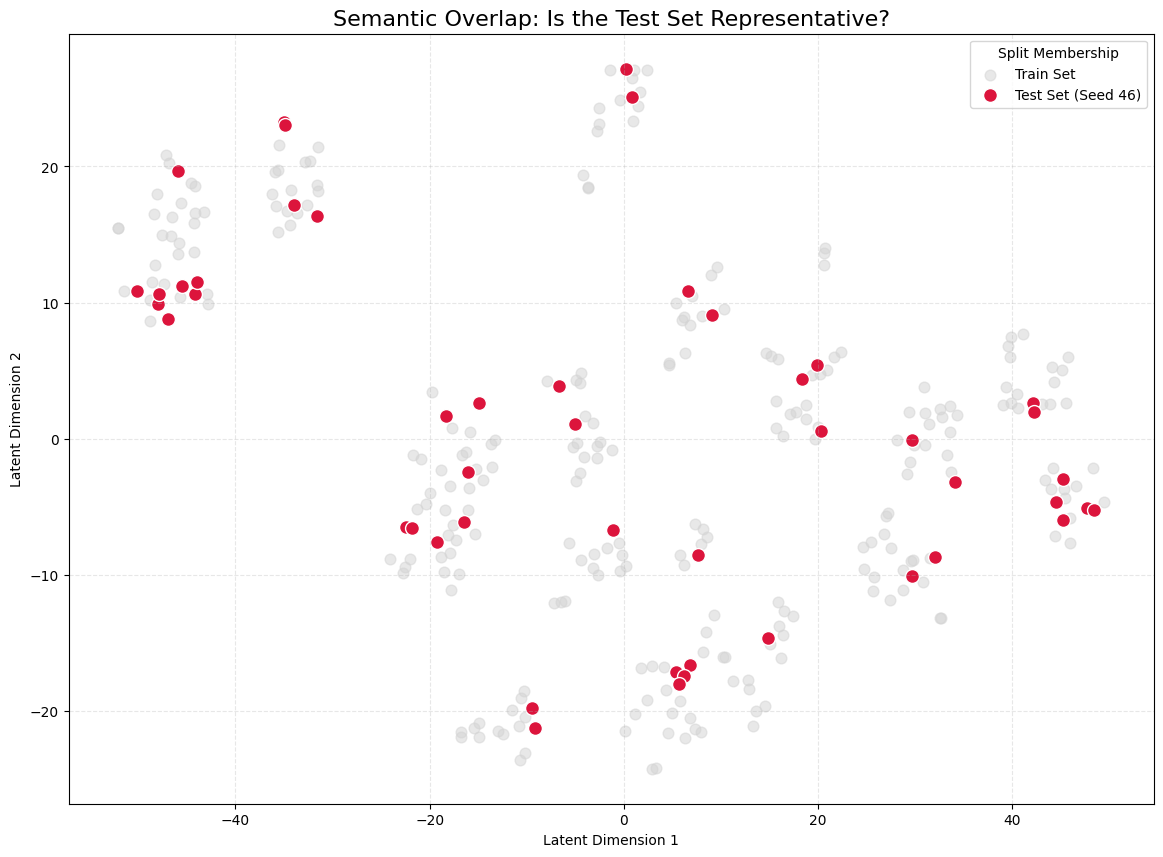


📊 FINAL CROSS-SPLIT DIVERSITY METRICS 📊
TRAIN Lexical Richness (TTR): 0.2668
TEST  Lexical Richness (TTR): 0.4721
Integrity Check: ⚠️ VARIANCE HIGH


In [ ]:
#@title [CELL 9.7] Final Comparative Audit (Train vs. Test vs. Full)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import numpy as np

# 1. SETUP DATA FOR COMPARISON
train_set['split'] = 'Train'
test_set['split'] = 'Test'
comparison_df = pd.concat([train_set, test_set])

# 2. PLOT DISTRIBUTION HEATMAPS
fig, axes = plt.subplots(1, 3, figsize=(24, 10), sharey=True)

sets = [
    (df, "1. FULL DATASET (N=313)"),
    (train_set, "2. TRAIN SET (N=265)"),
    (test_set, "3. TEST SET (N=48)")
]

for i, (data, title) in enumerate(sets):
    pivot = pd.crosstab(data['species_class'], data['target_category'])
    # Ensure all 8 categories exist in the pivot for alignment
    for cat in CORE_CATEGORIES:
        if cat not in pivot.columns: pivot[cat] = 0
    pivot = pivot[CORE_CATEGORIES]

    sns.heatmap(pivot, annot=True, cmap="YlGnBu", fmt='g', cbar=False, ax=axes[i])
    axes[i].set_title(title, fontsize=16)
    axes[i].set_xlabel("Target Category", fontsize=12)
    plt.setp(axes[i].get_xticklabels(), rotation=45, ha="right")

axes[0].set_ylabel("Parent Species Class", fontsize=14)
plt.suptitle("Categorical Consistency Audit (Phylogenetic Integrity)", fontsize=20, y=1.05)
plt.tight_layout()
plt.show()

# 3. LATENT SPACE OVERLAP (t-SNE)
print("\nProjecting Final Semantic Overlap Map...")
# Re-extract embeddings from cache in the correct order for comparison_df
final_embeddings = []
for tid in comparison_df['task_id']:
    final_embeddings.append(EMBEDDINGS_CACHE[tid])

matrix = np.array(final_embeddings)
pca_res = PCA(n_components=max(2, min(50, len(comparison_df)-1))).fit_transform(matrix)
vis_dims = TSNE(n_components=2, perplexity=15, random_state=42).fit_transform(pca_res)

plt.figure(figsize=(14, 10))
# Plot Train dots
train_idx = comparison_df[comparison_df['split'] == 'Train'].index
plt.scatter(vis_dims[:len(train_set), 0], vis_dims[:len(train_set), 1],
            color='lightgrey', label='Train Set', alpha=0.5, s=60)

# Plot Test dots in a vibrant color to see where they land
plt.scatter(vis_dims[len(train_set):, 0], vis_dims[len(train_set):, 1],
            color='crimson', label='Test Set (Seed 46)', edgecolors='white', linewidth=1, s=100)

plt.title('Semantic Overlap: Is the Test Set Representative?', fontsize=16)
plt.legend(loc='upper right', title="Split Membership")
plt.grid(True, linestyle='--', alpha=0.3)
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.show()

# 4. FINAL CROSS-SPLIT MATH
def get_metrics(data):
    texts = [f"{t['context_metadata']} {t['visual_cues']}" for _, t in data.iterrows()]
    words = " ".join(texts).lower().split()
    ttr = len(set(words)) / len(words)
    return ttr

print("\n" + "="*50)
print("📊 FINAL CROSS-SPLIT DIVERSITY METRICS 📊")
print("="*50)
print(f"TRAIN Lexical Richness (TTR): {get_metrics(train_set):.4f}")
print(f"TEST  Lexical Richness (TTR): {get_metrics(test_set):.4f}")
print(f"Integrity Check: { '✅ PASSED' if abs(get_metrics(train_set) - get_metrics(test_set)) < 0.1 else '⚠️ VARIANCE HIGH'}")
print("="*50)

In [ ]:
#@title [CELL 10] Official F.A.R.M. Benchmark Publication
from datasets import Dataset, DatasetDict

# 1. Convert our audited splits to HF format
# We remove the internal 'primary_citation' column used for splitting to keep it clean
farm_hf = DatasetDict({
    "train": Dataset.from_list(train_set.drop(columns=['primary_citation']).to_dict(orient='records')),
    "test": Dataset.from_list(test_set.drop(columns=['primary_citation']).to_dict(orient='records'))
})

# 2. Add metadata (Optional but professional)
farm_hf.set_format("python")

# ==========================================
# 🚀 PUSH TO HUGGING FACE
# ==========================================
HF_USERNAME = "oliveirabruno01"
DATASET_NAME = "AWW-bench"
REPO_ID = f"{HF_USERNAME}/{DATASET_NAME}"

print(f"Pushing Gold-Standard Benchmark to: https://huggingface.co/datasets/{REPO_ID}")

try:
    farm_hf.push_to_hub(REPO_ID)
    print("\n" + "🏆"*10)
    print("ULTIMATE SUCCESS! The F.A.R.M. Benchmark is LIVE.")
    print(f"Repo: https://huggingface.co/datasets/{REPO_ID}")
    print("🏆"*10)
except Exception as e:
    print(f"\n❌ Error pushing to hub: {e}")

Pushing Gold-Standard Benchmark to: https://huggingface.co/datasets/oliveirabruno01/AWW-bench


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              : 100%|##########| 52.3kB / 52.3kB            

README.md:   0%|          | 0.00/773 [00:00<?, ?B/s]


🏆🏆🏆🏆🏆🏆🏆🏆🏆🏆
ULTIMATE SUCCESS! The F.A.R.M. Benchmark is LIVE.
Repo: https://huggingface.co/datasets/oliveirabruno01/AWW-bench
🏆🏆🏆🏆🏆🏆🏆🏆🏆🏆
